# Experiments 8, 9 - Effect of Attention Type and Attention Position in a
# Pretrained ResNet50
CS3807 Deep Learning Lab
Dataset: TensorFlow Flowers (tf_flowers) - 5 classes

Note: this script trains ~20 ResNet50-based models in sequence (attention-type
ablation, attention-position ablation, multi-position study, attention-order
study, kernel-size study, and the additional-mechanism comparison), plus
Grad-CAM and internal attention-map visualisation. ResNet50 fine-tuning is
far heavier than the small MNIST models used in earlier experiments, so the
epoch counts below are kept deliberately small (a frozen-backbone phase of a
few epochs + a short fine-tune phase) to keep total runtime reasonable on a
single GPU. Increase EPOCHS_HEAD / EPOCHS_FT for a more thorough run. All
metric values printed below come from this script's own execution.

In [1]:
# Kaggle setup: make sure GPU is enabled (Settings -> Accelerator -> GPU)
# for reasonable ResNet50 training speed, and Internet is ON (Settings ->
# Internet) so the flowers dataset and ImageNet weights can download.
# tensorflow, pandas, numpy, matplotlib and scikit-learn are already
# preinstalled in the Kaggle Python environment - nothing else to install.
# (tensorflow_datasets is intentionally NOT used/installed here: on some
# Kaggle images it pulls a newer tensorflow_metadata/protobuf than the
# preinstalled TensorFlow runtime expects, causing a protobuf
# gencode/runtime version-mismatch error.)

In [46]:
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import pathlib

import tensorflow as tf
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.applications.resnet50 import ResNet50, preprocess_input

from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                              confusion_matrix)

import warnings, logging
warnings.filterwarnings("ignore")
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
tf.get_logger().setLevel("ERROR")

np.random.seed(42)
tf.random.set_seed(42)

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Liberation Serif', 'Nimbus Roman', 'Times New Roman', 'DejaVu Serif']
plt.rcParams['savefig.dpi'] = 600
plt.rcParams['figure.dpi'] = 600

IMG_SIZE = 224
NUM_CLASSES = 5
CLASS_NAMES = ['daisy', 'dandelion', 'roses', 'sunflowers', 'tulips']

# keep the whole lab short to run - lower these (and EPOCHS_*) if you have more
# compute/time available, or raise them for a more thorough report
SUBSET_PER_CLASS = 160          # images per class used (tf_flowers has ~600-900/class)
EPOCHS_HEAD = 4                 # Section 20 step 7-8: train head with backbone frozen
EPOCHS_FT = 3                   # Section 20 step 9-10: fine-tune last stage
BATCH_SIZE = 16
LR_HEAD = 1e-3                  # Section 20 recommended lr for new layers
LR_FT = 1e-4                    # Section 20 recommended fine-tuning lr


def save_plot(filename):
    plt.savefig(f"{filename}.eps", format='eps', dpi=600, bbox_inches='tight')
    print(f"saved {filename}.eps")

## Section 3: Dataset (tf_flowers) and Section 3.1-3.2: Preprocessing / Split

In [3]:
# tf_flowers has no official train/val/test split, so we load every image into
# memory once, shuffle with a FIXED seed, and carve out 70:15:15. Every single
# experiment below reuses exactly these same index arrays, so differences in
# performance come only from the model, never from the data (Section 34).
#
# Loaded directly from the original flower_photos tarball (the same images
# tf_flowers wraps) via tf.keras.utils.get_file, so no tensorflow_datasets /
# tensorflow_metadata dependency is needed - this avoids the protobuf
# gencode/runtime version conflict that tensorflow_datasets can trigger on
# some Kaggle/Colab images.
FLOWERS_URL = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
archive_path = pathlib.Path(tf.keras.utils.get_file(
    "flower_photos.tgz", origin=FLOWERS_URL, extract=True, cache_dir="/tmp/flowers_cache"))

# where get_file actually puts the extracted folder differs slightly across
# TF/Keras versions, so search for it instead of assuming one fixed layout
search_roots = [archive_path.with_suffix(''), archive_path.parent, pathlib.Path("/tmp/flowers_cache")]
data_dir = None
for root in search_roots:
    hits = list(root.rglob("daisy")) if root.exists() else []
    if hits:
        data_dir = hits[0].parent
        break
if data_dir is None:
    raise FileNotFoundError(
        f"Could not locate the extracted flower_photos folder under any of: {search_roots}. "
        "Check that the Kaggle notebook has Internet access enabled (Settings -> Internet).")
print("Using flowers data directory:", data_dir)

images, labels = [], []
per_class_count = {c: 0 for c in range(NUM_CLASSES)}
for class_idx, class_name in enumerate(CLASS_NAMES):
    file_list = sorted((data_dir / class_name).glob("*.jpg"))
    if not file_list:
        raise FileNotFoundError(f"No .jpg files found for class '{class_name}' under {data_dir / class_name}")
    rng_files = np.random.RandomState(42 + class_idx)
    rng_files.shuffle(file_list)
    for fpath in file_list[:SUBSET_PER_CLASS]:
        img_bytes = tf.io.read_file(str(fpath))
        img = tf.io.decode_jpeg(img_bytes, channels=3)
        img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE)).numpy().astype('uint8')
        images.append(img)
        labels.append(class_idx)
        per_class_count[class_idx] += 1

images = np.stack(images)
labels = np.array(labels)
print("Loaded subset:", images.shape, "class counts:", per_class_count)

rng = np.random.RandomState(42)
perm = rng.permutation(len(images))
images, labels = images[perm], labels[perm]

n = len(images)
n_train = int(0.70 * n)
n_val = int(0.15 * n)
x_train_raw = images[:n_train]
y_train = labels[:n_train]
x_val_raw = images[n_train:n_train + n_val]
y_val = labels[n_train:n_train + n_val]
x_test_raw = images[n_train + n_val:]
y_test = labels[n_train + n_val:]

y_train_oh = tf.keras.utils.to_categorical(y_train, NUM_CLASSES)
y_val_oh = tf.keras.utils.to_categorical(y_val, NUM_CLASSES)
y_test_oh = tf.keras.utils.to_categorical(y_test, NUM_CLASSES)

print("Train:", x_train_raw.shape, " Val:", x_val_raw.shape, " Test:", x_test_raw.shape)
print("Split ratio:", len(x_train_raw) / n, len(x_val_raw) / n, len(x_test_raw) / n)

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Using flowers data directory: /tmp/.keras/datasets/flower_photos_extracted/flower_photos


I0000 00:00:1792423809.986365      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792423809.990520      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Loaded subset: (800, 224, 224, 3) class counts: {0: 160, 1: 160, 2: 160, 3: 160, 4: 160}
Train: (560, 224, 224, 3)  Val: (120, 224, 224, 3)  Test: (120, 224, 224, 3)
Split ratio: 0.7 0.15 0.15


saved sample_images_per_class.eps


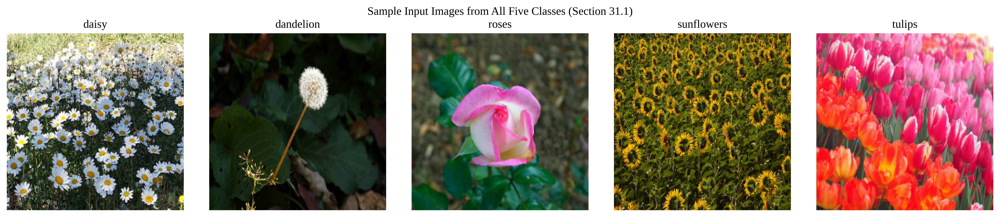

In [47]:
# Section 31 (required visualisation #1): one sample input image from each of
# the five classes.
fig, axes = plt.subplots(1, NUM_CLASSES, figsize=(15, 3.2))
for class_idx, class_name in enumerate(CLASS_NAMES):
    sample_pos = np.where(y_train == class_idx)[0][0]
    axes[class_idx].imshow(x_train_raw[sample_pos])
    axes[class_idx].set_title(class_name)
    axes[class_idx].axis('off')
plt.suptitle("Sample Input Images from All Five Classes (Section 31.1)")
plt.tight_layout()
save_plot("sample_images_per_class")
plt.show()

In [5]:
# Section 3.1 augmentation layers (train-time only) + ImageNet preprocessing.
# These Keras layers are part of every model built below, so every model in
# every experiment uses the identical augmentation strategy (Section 34).
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.08, 0.08),
    layers.RandomContrast(0.1),
], name="augmentation")


def make_dataset(x_raw, y_oh, training, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((x_raw, y_oh))
    if training:
        ds = ds.shuffle(len(x_raw), seed=42)
    ds = ds.batch(batch_size)

    def prep(x, y):
        x = tf.cast(x, tf.float32)
        if training:
            x = augmentation(x, training=True)
        x = preprocess_input(x)  # ResNet50-expected preprocessing (Section 3.1)
        return x, y

    ds = ds.map(prep, num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)


train_ds = make_dataset(x_train_raw, y_train_oh, training=True)
val_ds = make_dataset(x_val_raw, y_val_oh, training=False)
test_ds = make_dataset(x_test_raw, y_test_oh, training=False)

# single un-augmented, un-batched test tensor, used for Grad-CAM / attention
# visualisation and for the plain-numpy predict() calls in the metric helpers
x_test_pp = preprocess_input(x_test_raw.astype('float32'))

## Section 4-6: ResNet50 Stage Feature Hierarchy (reference, printed once)

In [6]:
_probe = ResNet50(weights='imagenet', include_top=False, input_shape=(IMG_SIZE, IMG_SIZE, 3))
# simple P1-P4 -> ResNet50 layer-name lookup, used by build_attention_model below
STAGE_TO_LAYER = {
    "P1": "conv2_block3_out",   # after conv2_x
    "P2": "conv3_block4_out",   # after conv3_x
    "P3": "conv4_block6_out",   # after conv4_x
    "P4": "conv5_block3_out",   # after conv5_x
}
STAGE_DESCRIPTION = {"P1": "after conv2_x", "P2": "after conv3_x",
                      "P3": "after conv4_x", "P4": "after conv5_x"}
print("Section 7 - candidate attention positions and their feature dimensions:")
for label, layer_name in STAGE_TO_LAYER.items():
    shp = _probe.get_layer(layer_name).output.shape
    print(f"  {label} ({STAGE_DESCRIPTION[label]}): layer='{layer_name}'  shape={shp}")
del _probe

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Section 7 - candidate attention positions and their feature dimensions:
  P1 (after conv2_x): layer='conv2_block3_out'  shape=(None, 56, 56, 256)
  P2 (after conv3_x): layer='conv3_block4_out'  shape=(None, 28, 28, 512)
  P3 (after conv4_x): layer='conv4_block6_out'  shape=(None, 14, 14, 1024)
  P4 (after conv5_x): layer='conv5_block3_out'  shape=(None, 7, 7, 2048)


## Sections 9-12: Attention Modules (Channel, Spatial, Sequential, Self-Attention)
## plus Section 19's additional mechanisms (ECA, Coordinate Attention)

In [7]:
class ResidualScale(layers.Layer):
    """Learnable scalar gamma for the residual self-attention formulation
    F_SA = F + gamma * reshape(Y) (Section 12)."""

    def build(self, input_shape):
        self.gamma = self.add_weight(name="gamma", shape=(), initializer="zeros", trainable=True)

    def call(self, inputs):
        x, y = inputs
        return x + self.gamma * y


def channel_attention(x, reduction=16, name="ca"):
    """Section 9: Mc(F) = sigma(W2 delta(W1 z)),  Fc = F (x) Mc(F)."""
    channels = x.shape[-1]
    z = layers.GlobalAveragePooling2D(name=f"{name}_gap")(x)
    h = layers.Dense(max(channels // reduction, 1), activation='relu', name=f"{name}_fc1")(z)
    m = layers.Dense(channels, activation='sigmoid', name=f"{name}_fc2")(h)
    scale = layers.Reshape((1, 1, channels), name=f"{name}_reshape")(m)
    return layers.Multiply(name=f"{name}_scale")([x, scale])


def spatial_attention(x, kernel_size=7, name="sa"):
    """Section 10: Fs = [Favg || Fmax], Ms(F) = sigma(Conv7x7(Fs)), F' = F (x) Ms(F)."""
    avg_pool = layers.Lambda(lambda t: tf.reduce_mean(t, axis=-1, keepdims=True),
                              name=f"{name}_avgpool")(x)
    max_pool = layers.Lambda(lambda t: tf.reduce_max(t, axis=-1, keepdims=True),
                              name=f"{name}_maxpool")(x)
    concat = layers.Concatenate(axis=-1, name=f"{name}_concat")([avg_pool, max_pool])
    attn_map = layers.Conv2D(1, kernel_size, padding='same', activation='sigmoid',
                              name=f"{name}_map")(concat)
    out = layers.Multiply(name=f"{name}_scale")([x, attn_map])
    return out


def channel_spatial_attention(x, reduction=16, kernel_size=7, name="csa", order="cs"):
    """Section 11 (also used as CBAM in Section 19): sequential channel then
    spatial attention (order='cs'), or spatial then channel (order='sc') for
    the Section 17 attention-order ablation."""
    if order == "cs":
        x = channel_attention(x, reduction, name=f"{name}_c")
        x = spatial_attention(x, kernel_size, name=f"{name}_s")
    else:
        x = spatial_attention(x, kernel_size, name=f"{name}_s")
        x = channel_attention(x, reduction, name=f"{name}_c")
    return x


def self_attention(x, name="selfattn", key_ratio=8):
    """Section 12: lightweight self-attention. Q,K,V are 1x1-dense projections
    over the flattened H*W locations; A = softmax(QK^T / sqrt(d)); residual
    output F + gamma * reshape(AV)."""
    h, w, c = x.shape[1], x.shape[2], x.shape[3]
    n = h * w
    d = max(c // key_ratio, 1)
    flat = layers.Reshape((n, c), name=f"{name}_flatten")(x)
    q = layers.Dense(d, name=f"{name}_q")(flat)
    k = layers.Dense(d, name=f"{name}_k")(flat)
    v = layers.Dense(c, name=f"{name}_v")(flat)
    logits = layers.Lambda(
        lambda t: tf.matmul(t[0], t[1], transpose_b=True) / tf.sqrt(tf.cast(d, tf.float32)),
        name=f"{name}_logits")([q, k])
    attn = layers.Softmax(axis=-1, name=f"{name}_softmax")(logits)
    y = layers.Lambda(lambda t: tf.matmul(t[0], t[1]), name=f"{name}_matmul")([attn, v])
    y = layers.Reshape((h, w, c), name=f"{name}_reshape")(y)
    return ResidualScale(name=f"{name}_residual")([x, y])


def eca_attention(x, name="eca", gamma=2, b=1):
    """Section 19: Efficient Channel Attention - a 1D conv over channels with
    an adaptively-chosen odd kernel size k, instead of the two dense layers
    used by SE/channel attention."""
    channels = x.shape[-1]
    k = int(abs((np.log2(channels) / gamma) + b / gamma))
    k = k if k % 2 == 1 else k + 1
    k = max(k, 3)
    z = layers.GlobalAveragePooling2D(name=f"{name}_gap")(x)
    r = layers.Reshape((channels, 1), name=f"{name}_reshape1")(z)
    conv = layers.Conv1D(1, kernel_size=k, padding='same', use_bias=False, name=f"{name}_conv1d")(r)
    sig = layers.Activation('sigmoid', name=f"{name}_sigmoid")(conv)
    scale = layers.Reshape((1, 1, channels), name=f"{name}_reshape2")(sig)
    return layers.Multiply(name=f"{name}_scale")([x, scale])


def coordinate_attention(x, reduction=16, name="coord"):
    """Section 19: Coordinate Attention - pools along H and W separately,
    jointly encodes them, then applies two direction-specific gates."""
    h, w, c = x.shape[1], x.shape[2], x.shape[3]
    pool_h = layers.Lambda(lambda t: tf.reduce_mean(t, axis=2, keepdims=True), name=f"{name}_poolh")(x)
    pool_w = layers.Lambda(lambda t: tf.reduce_mean(t, axis=1, keepdims=True), name=f"{name}_poolw")(x)
    pool_w = layers.Permute((2, 1, 3), name=f"{name}_permute1")(pool_w)
    concat = layers.Concatenate(axis=1, name=f"{name}_concat")([pool_h, pool_w])
    mid_c = max(c // reduction, 8)
    y = layers.Conv2D(mid_c, 1, padding='same', name=f"{name}_conv1")(concat)
    y = layers.BatchNormalization(name=f"{name}_bn")(y)
    y = layers.Activation('swish', name=f"{name}_act")(y)
    h_part = layers.Lambda(lambda t: t[:, :h, :, :], name=f"{name}_split_h")(y)
    w_part = layers.Lambda(lambda t: t[:, h:, :, :], name=f"{name}_split_w")(y)
    w_part = layers.Permute((2, 1, 3), name=f"{name}_permute2")(w_part)
    attn_h = layers.Conv2D(c, 1, padding='same', activation='sigmoid', name=f"{name}_gate_h")(h_part)
    attn_w = layers.Conv2D(c, 1, padding='same', activation='sigmoid', name=f"{name}_gate_w")(w_part)
    return layers.Multiply(name=f"{name}_scale")([x, attn_h, attn_w])

## Section 13: Inserting Attention into a Pretrained ResNet50 (graph surgery)
## Section 20: Transfer-Learning Strategy

In [8]:
def build_attention_model(insertions, dropout=0.3, model_name="model"):
    """Builds Input -> ResNet50 (ImageNet weights) -> attention block(s) ->
    GAP -> Dropout -> Dense(5) (Section 8/20).

    `insertions` is a list of (stage_label, attention_fn) pairs, e.g.
    [("P3", lambda t: channel_attention(t, name="p3_ca"))]. Internally every
    ResNet50 layer is replayed in topological order so every layer BEFORE the
    chosen cut keeps its original pretrained weights/tensor untouched, and the
    attention_fn is spliced in exactly where Section 13 asks for it:
        previous_stage -> Attention -> next_stage
    Because every layer object in keras.applications.ResNet50 is used exactly
    once (no weight sharing across multiple calls), replaying `layer(...)` on
    freshly-computed inputs reconstructs an equivalent graph with the same
    weights, with the attention block(s) now part of the forward pass.
    """
    cut_map = {STAGE_TO_LAYER[label]: fn for label, fn in insertions}

    inputs = Input(shape=(IMG_SIZE, IMG_SIZE, 3), name=f"{model_name}_input")
    base_model = ResNet50(weights='imagenet', include_top=False, input_tensor=inputs)

    new_outputs = {}
    for layer in base_model.layers:
        if isinstance(layer, tf.keras.layers.InputLayer):
            new_outputs[layer.name] = layer.output
            continue
        # node 0 is always the layer's ORIGINAL call, made automatically by the
        # ResNet50() constructor above - we read its inputs, then re-call the
        # layer on our own (possibly attention-modified) tensors, which adds a
        # new node without disturbing node 0. `node.input_tensors` plus each
        # tensor's `_keras_history` are used (rather than the older
        # Node.inbound_layers / Layer.get_input_at, both removed in Keras 3)
        # so the surgery works on Keras 2 and Keras 3 alike.
        node = layer._inbound_nodes[0]
        old_inputs = node.input_tensors
        if not isinstance(old_inputs, (list, tuple)):
            old_inputs = [old_inputs]
        call_inputs = [new_outputs[t._keras_history[0].name] for t in old_inputs]
        call_inputs = call_inputs[0] if len(call_inputs) == 1 else call_inputs
        out = layer(call_inputs)
        if layer.name in cut_map:
            pre_shape = tuple(out.shape)       # Section 13/38.1: feature
            out = cut_map[layer.name](out)     # dimensions immediately before
            post_shape = tuple(out.shape)       # and after the attention block
            print(f"  [{model_name}] attention at layer '{layer.name}': "
                  f"input shape {pre_shape} -> output shape {post_shape} "
                  f"({'unchanged' if pre_shape == post_shape else 'CHANGED'})")
        new_outputs[layer.name] = out

    backbone_out = new_outputs[base_model.layers[-1].name]
    x = layers.GlobalAveragePooling2D(name=f"{model_name}_gap")(backbone_out)
    x = layers.Dropout(dropout, name=f"{model_name}_dropout")(x)
    outputs = layers.Dense(NUM_CLASSES, activation='softmax', name=f"{model_name}_dense")(x)
    model = Model(inputs, outputs, name=model_name)
    return model, base_model


def get_layer_output(model, layer_name):
    """Every ORIGINAL ResNet50 layer gets called twice inside
    build_attention_model: once by the ResNet50() constructor itself (an
    unused throwaway graph) and once by our graph-surgery replay (the real
    graph this `model` actually uses). That leaves such layers with two
    inbound nodes, so a plain `layer.output` is ambiguous and raises an
    error (and Keras 3 dropped the old `get_output_at` helper entirely).
    This always returns the output tensor of the LAST node - i.e. the one
    actually wired into this particular `model` - via `node.output_tensors`,
    which is stable across Keras 2 and Keras 3. Safe for any layer name,
    attention-specific or original ResNet50."""
    layer = model.get_layer(layer_name)
    node = layer._inbound_nodes[-1]
    out = node.output_tensors
    return out[0] if isinstance(out, (list, tuple)) else out


def freeze_backbone(base_model):
    for layer in base_model.layers:
        layer.trainable = False


def unfreeze_last_stage(base_model, from_layer="conv5_block1_1_conv"):
    """Section 20 step 9: unfreeze conv5_x (the final ResNet50 stage) only."""
    found = False
    for layer in base_model.layers:
        if layer.name == from_layer:
            found = True
        layer.trainable = found


def train_two_phase(model, base_model, name,
                     epochs_head=EPOCHS_HEAD, epochs_ft=EPOCHS_FT):
    """Section 20's two-phase strategy: freeze ResNet50, train the new
    attention + classifier layers, then unfreeze conv5_x and fine-tune with a
    smaller learning rate. Returns a combined keras History-like dict so the
    accuracy/loss curves (Section 24.1-24.2) span both phases."""
    freeze_backbone(base_model)
    model.compile(optimizer=tf.keras.optimizers.Adam(LR_HEAD),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    start = time.time()
    h1 = model.fit(train_ds, validation_data=val_ds, epochs=epochs_head, verbose=0)

    unfreeze_last_stage(base_model)
    model.compile(optimizer=tf.keras.optimizers.Adam(LR_FT),
                  loss='categorical_crossentropy', metrics=['accuracy'])
    h2 = model.fit(train_ds, validation_data=val_ds, epochs=epochs_ft, verbose=0)
    elapsed = time.time() - start

    history = {k: h1.history[k] + h2.history[k] for k in h1.history}
    print(f"[{name}] final train acc={history['accuracy'][-1]:.3f}  "
          f"val acc={history['val_accuracy'][-1]:.3f}  train time={elapsed:.1f}s")
    return history, elapsed

## Sections 22-23: Evaluation Metrics and Result-Table Helpers

In [9]:
def evaluate_model(model, name, position_label=""):
    """Section 22: accuracy, macro precision/recall/F1, trainable/total
    parameters, average inference time per image (Section 23's result row)."""
    y_pred_proba = model.predict(x_test_pp, batch_size=BATCH_SIZE, verbose=0)
    y_pred = np.argmax(y_pred_proba, axis=1)

    acc = accuracy_score(y_test, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='macro', zero_division=0)
    cm = confusion_matrix(y_test, y_pred)

    trainable_params = int(sum(np.prod(v.shape) for v in model.trainable_weights))
    total_params = model.count_params()

    # average single-image inference time, measured after a short warm-up
    _ = model.predict(x_test_pp[:4], verbose=0)
    n_timed = min(50, len(x_test_pp))
    start = time.time()
    for i in range(n_timed):
        model.predict(x_test_pp[i:i + 1], verbose=0)
    inf_time = (time.time() - start) / n_timed

    row = {"Model": name, "Position": position_label, "Accuracy": acc,
           "Precision": prec, "Recall": rec, "F1": f1,
           "Trainable Params": trainable_params, "Total Params": total_params,
           "Inference Time (s/img)": inf_time}
    print(f"[{name}] acc={acc:.3f} prec={prec:.3f} rec={rec:.3f} f1={f1:.3f} "
          f"params={total_params:,} inf={inf_time*1000:.1f} ms/img")
    return row, cm, y_pred


def run_experiment(insertions, name, position_label=""):
    """Builds, trains and evaluates one attention configuration; returns the
    Section 23 result row, its history (for the Section 24 curves), the
    trained model and the confusion matrix."""
    model, base_model = build_attention_model(insertions, model_name=name.replace(" ", "_"))
    history, _ = train_two_phase(model, base_model, name)
    row, cm, y_pred = evaluate_model(model, name, position_label)
    return row, history, model, cm, y_pred


results = []       # Section 23 required main result table, one row per model
histories = {}      # for Section 24.1-24.2 accuracy/loss curves
trained_models = {}  # kept around for Section 26-30 qualitative analysis

## Section 8: Baseline Model

In [10]:
row, hist, model, cm, y_pred = run_experiment([], "Baseline", position_label="-")
results.append(row); histories["Baseline"] = hist; trained_models["Baseline"] = model
cm_baseline = cm

I0000 00:00:1792423839.570402     139 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


[Baseline] final train acc=0.968  val acc=0.833  train time=80.5s
[Baseline] acc=0.858 prec=0.855 rec=0.860 f1=0.856 params=23,597,957 inf=156.6 ms/img


## Section 14: Main Experiment 1 - Attention-Type Ablation (fixed at P3)

In [11]:
# A0 (baseline) is already trained above. A1-A5 all insert attention right
# after conv4_x (P3), changing only the attention TYPE (Section 34).
type_ablation_specs = {
    "A1_Channel_P3": [("P3", lambda t: channel_attention(t, name="a1_ca"))],
    "A2_Spatial_P3": [("P3", lambda t: spatial_attention(t, name="a2_sa"))],
    "A3_ChannelSpatial_P3": [("P3", lambda t: channel_spatial_attention(t, name="a3_csa"))],
    "A4_SelfAttention_P3": [("P3", lambda t: self_attention(t, name="a4_self"))],
    "A5_Combined_P3": [("P3", lambda t: self_attention(channel_spatial_attention(t, name="a5_csa"), name="a5_self"))],
}
for name, spec in type_ablation_specs.items():
    row, hist, model, cm, y_pred = run_experiment(spec, name, position_label="P3")
    results.append(row); histories[name] = hist; trained_models[name] = model

  [A1_Channel_P3] attention at layer 'conv4_block6_out': input shape (None, 14, 14, 1024) -> output shape (None, 14, 14, 1024) (unchanged)
[A1_Channel_P3] final train acc=0.966  val acc=0.833  train time=77.1s
[A1_Channel_P3] acc=0.875 prec=0.871 rec=0.876 f1=0.871 params=23,730,117 inf=143.1 ms/img
  [A2_Spatial_P3] attention at layer 'conv4_block6_out': input shape (None, 14, 14, 1024) -> output shape (None, 14, 14, 1024) (unchanged)
[A2_Spatial_P3] final train acc=0.975  val acc=0.842  train time=77.5s
[A2_Spatial_P3] acc=0.858 prec=0.856 rec=0.857 f1=0.854 params=23,598,056 inf=143.9 ms/img
  [A3_ChannelSpatial_P3] attention at layer 'conv4_block6_out': input shape (None, 14, 14, 1024) -> output shape (None, 14, 14, 1024) (unchanged)
[A3_ChannelSpatial_P3] final train acc=0.986  val acc=0.858  train time=79.8s
[A3_ChannelSpatial_P3] acc=0.900 prec=0.896 rec=0.901 f1=0.896 params=23,730,216 inf=145.1 ms/img
  [A4_SelfAttention_P3] attention at layer 'conv4_block6_out': input shape (

## Section 15: Main Experiment 2 - Attention-Position Ablation
## (fixed at Channel -> Spatial, moved across P2/P3/P4. P1/B1 is intentionally
## skipped per Section 7's own guidance to focus on P2-P4, since P1's high
## resolution substantially increases compute; it is also absent from
## Section 23's result table and Section 35's minimum mandatory set.)

In [12]:
position_ablation_specs = {
    "B2_ChannelSpatial_P2": [("P2", lambda t: channel_spatial_attention(t, name="b2_csa"))],
    "B3_ChannelSpatial_P3": [("P3", lambda t: channel_spatial_attention(t, name="b3_csa"))],
    "B4_ChannelSpatial_P4": [("P4", lambda t: channel_spatial_attention(t, name="b4_csa"))],
}
position_labels = {"B2_ChannelSpatial_P2": "P2", "B3_ChannelSpatial_P3": "P3", "B4_ChannelSpatial_P4": "P4"}
# B3 (Channel+Spatial @ P3) is identical in configuration to A3 above, so it is
# not re-trained here - A3's row/model is reused directly for the P3 point of
# this ablation, matching the manual's "identical settings" requirement.
for name, spec in position_ablation_specs.items():
    if name == "B3_ChannelSpatial_P3":
        continue
    row, hist, model, cm, y_pred = run_experiment(spec, name, position_label=position_labels[name])
    results.append(row); histories[name] = hist; trained_models[name] = model
trained_models["B3_ChannelSpatial_P3"] = trained_models["A3_ChannelSpatial_P3"]

  [B2_ChannelSpatial_P2] attention at layer 'conv3_block4_out': input shape (None, 28, 28, 512) -> output shape (None, 28, 28, 512) (unchanged)
[B2_ChannelSpatial_P2] final train acc=0.898  val acc=0.758  train time=82.3s
[B2_ChannelSpatial_P2] acc=0.783 prec=0.793 rec=0.782 f1=0.781 params=23,631,368 inf=145.0 ms/img
  [B4_ChannelSpatial_P4] attention at layer 'conv5_block3_out': input shape (None, 7, 7, 2048) -> output shape (None, 7, 7, 2048) (unchanged)
[B4_ChannelSpatial_P4] final train acc=0.988  val acc=0.858  train time=78.7s
[B4_ChannelSpatial_P4] acc=0.875 prec=0.872 rec=0.868 f1=0.870 params=24,124,520 inf=146.6 ms/img


## Section 16: Main Experiment 3 - Multiple Attention Positions

In [13]:
multi_position_specs = {
    "C_P3_only": [("P3", lambda t: channel_spatial_attention(t, name="c3_csa"))],
    "C_P4_only": [("P4", lambda t: channel_spatial_attention(t, name="c4_csa"))],
    "C_P3_plus_P4": [("P3", lambda t: channel_spatial_attention(t, name="c34a_csa")),
                      ("P4", lambda t: channel_spatial_attention(t, name="c34b_csa"))],
    "C_P2_P3_P4_extended": [("P2", lambda t: channel_spatial_attention(t, name="c234a_csa")),
                              ("P3", lambda t: channel_spatial_attention(t, name="c234b_csa")),
                              ("P4", lambda t: channel_spatial_attention(t, name="c234c_csa"))],
}
for name, spec in multi_position_specs.items():
    row, hist, model, cm, y_pred = run_experiment(spec, name, position_label=str([s[0] for s in spec]))
    results.append(row); histories[name] = hist; trained_models[name] = model

  [C_P3_only] attention at layer 'conv4_block6_out': input shape (None, 14, 14, 1024) -> output shape (None, 14, 14, 1024) (unchanged)
[C_P3_only] final train acc=0.959  val acc=0.875  train time=80.2s
[C_P3_only] acc=0.850 prec=0.861 rec=0.856 f1=0.852 params=23,730,216 inf=144.1 ms/img
  [C_P4_only] attention at layer 'conv5_block3_out': input shape (None, 7, 7, 2048) -> output shape (None, 7, 7, 2048) (unchanged)
[C_P4_only] final train acc=0.980  val acc=0.833  train time=77.8s
[C_P4_only] acc=0.900 prec=0.905 rec=0.900 f1=0.900 params=24,124,520 inf=143.2 ms/img
  [C_P3_plus_P4] attention at layer 'conv4_block6_out': input shape (None, 14, 14, 1024) -> output shape (None, 14, 14, 1024) (unchanged)
  [C_P3_plus_P4] attention at layer 'conv5_block3_out': input shape (None, 7, 7, 2048) -> output shape (None, 7, 7, 2048) (unchanged)
[C_P3_plus_P4] final train acc=0.955  val acc=0.842  train time=82.0s
[C_P3_plus_P4] acc=0.892 prec=0.896 rec=0.881 f1=0.884 params=24,256,779 inf=150.4 m

## Section 17: Main Experiment 4 - Attention Order (Channel->Spatial vs Spatial->Channel)

In [14]:
order_specs = {
    "D_ChannelThenSpatial_P3": [("P3", lambda t: channel_spatial_attention(t, name="d_cs", order="cs"))],
    "D_SpatialThenChannel_P3": [("P3", lambda t: channel_spatial_attention(t, name="d_sc", order="sc"))],
}
for name, spec in order_specs.items():
    row, hist, model, cm, y_pred = run_experiment(spec, name, position_label="P3")
    results.append(row); histories[name] = hist; trained_models[name] = model

  [D_ChannelThenSpatial_P3] attention at layer 'conv4_block6_out': input shape (None, 14, 14, 1024) -> output shape (None, 14, 14, 1024) (unchanged)
[D_ChannelThenSpatial_P3] final train acc=0.982  val acc=0.842  train time=77.9s
[D_ChannelThenSpatial_P3] acc=0.875 prec=0.877 rec=0.881 f1=0.876 params=23,730,216 inf=142.9 ms/img
  [D_SpatialThenChannel_P3] attention at layer 'conv4_block6_out': input shape (None, 14, 14, 1024) -> output shape (None, 14, 14, 1024) (unchanged)
[D_SpatialThenChannel_P3] final train acc=0.979  val acc=0.842  train time=80.5s
[D_SpatialThenChannel_P3] acc=0.875 prec=0.872 rec=0.876 f1=0.873 params=23,730,216 inf=145.7 ms/img


## Section 18: Main Experiment 5 - Spatial Attention Kernel Size

In [15]:
kernel_rows = []
for k in [3, 5, 7]:
    name = f"E_SpatialAttention_k{k}_P3"
    spec = [("P3", lambda t, k=k: spatial_attention(t, kernel_size=k, name=f"e{k}_sa"))]
    row, hist, model, cm, y_pred = run_experiment(spec, name, position_label="P3")
    results.append(row); histories[name] = hist; trained_models[name] = model
    kernel_rows.append({"Spatial Kernel": f"{k}x{k}", "Accuracy": row["Accuracy"],
                         "Macro F1": row["F1"], "Inference Time": row["Inference Time (s/img)"]})

print("\nSection 18 - Spatial Attention Kernel-Size Table:")
print(pd.DataFrame(kernel_rows).to_string(index=False))

# Inference: a larger receptive field lets the spatial-attention convolution
# aggregate context from a wider neighbourhood before deciding which locations
# matter. Whether that is worth the extra compute is exactly the question the
# table above answers - compare the Accuracy/F1 change against the Inference
# Time change across k=3,5,7 for this run.

  [E_SpatialAttention_k3_P3] attention at layer 'conv4_block6_out': input shape (None, 14, 14, 1024) -> output shape (None, 14, 14, 1024) (unchanged)
[E_SpatialAttention_k3_P3] final train acc=0.975  val acc=0.833  train time=76.4s
[E_SpatialAttention_k3_P3] acc=0.883 prec=0.877 rec=0.884 f1=0.879 params=23,597,976 inf=140.7 ms/img
  [E_SpatialAttention_k5_P3] attention at layer 'conv4_block6_out': input shape (None, 14, 14, 1024) -> output shape (None, 14, 14, 1024) (unchanged)
[E_SpatialAttention_k5_P3] final train acc=0.977  val acc=0.867  train time=76.2s
[E_SpatialAttention_k5_P3] acc=0.900 prec=0.912 rec=0.895 f1=0.901 params=23,598,008 inf=143.5 ms/img
  [E_SpatialAttention_k7_P3] attention at layer 'conv4_block6_out': input shape (None, 14, 14, 1024) -> output shape (None, 14, 14, 1024) (unchanged)
[E_SpatialAttention_k7_P3] final train acc=0.989  val acc=0.842  train time=75.9s
[E_SpatialAttention_k7_P3] acc=0.883 prec=0.884 rec=0.884 f1=0.883 params=23,598,056 inf=139.2 ms/im

## Section 19: Additional Task - Comparison with Established Attention Mechanisms
## (SE = our channel attention, CBAM = our channel+spatial; ECA and
## Coordinate Attention are implemented fresh as the two ADDITIONAL mechanisms)

In [31]:
additional_specs = {
    "F_SE_P3": [("P3", lambda t: channel_attention(t, name="f_se"))],
    "F_ECA_P3": [("P3", lambda t: eca_attention(t, name="f_eca"))],
    "F_CBAM_P3": [("P3", lambda t: channel_spatial_attention(t, name="f_cbam"))],
    "F_CoordinateAttention_P3": [("P3", lambda t: coordinate_attention(t, name="f_coord"))],
}
for name, spec in additional_specs.items():
    row, hist, model, cm, y_pred = run_experiment(spec, name, position_label="P3")
    results.append(row); histories[name] = hist; trained_models[name] = model

  [F_SE_P3] attention at layer 'conv4_block6_out': input shape (None, 14, 14, 1024) -> output shape (None, 14, 14, 1024) (unchanged)
[F_SE_P3] final train acc=0.975  val acc=0.817  train time=75.3s
[F_SE_P3] acc=0.867 prec=0.863 rec=0.869 f1=0.863 params=23,730,117 inf=141.1 ms/img
  [F_ECA_P3] attention at layer 'conv4_block6_out': input shape (None, 14, 14, 1024) -> output shape (None, 14, 14, 1024) (unchanged)
[F_ECA_P3] final train acc=0.971  val acc=0.792  train time=74.3s
[F_ECA_P3] acc=0.867 prec=0.872 rec=0.859 f1=0.862 params=23,597,962 inf=146.8 ms/img
  [F_CBAM_P3] attention at layer 'conv4_block6_out': input shape (None, 14, 14, 1024) -> output shape (None, 14, 14, 1024) (unchanged)
[F_CBAM_P3] final train acc=0.973  val acc=0.842  train time=78.2s
[F_CBAM_P3] acc=0.867 prec=0.866 rec=0.867 f1=0.865 params=23,730,216 inf=148.9 ms/img
  [F_CoordinateAttention_P3] attention at layer 'conv4_block6_out': input shape (None, 14, 14, 1024) -> output shape (None, 14, 14, 1024) (unc

In [32]:
results_df = pd.DataFrame(results)
print("\nSection 23 - Required Main Result Table (full):")
print(results_df.to_string(index=False))


Section 23 - Required Main Result Table (full):
                   Model           Position  Accuracy  Precision   Recall       F1  Trainable Params  Total Params  Inference Time (s/img)
                Baseline                  -  0.858333   0.855350 0.860466 0.855876          14986245      23597957                0.156555
           A1_Channel_P3                 P3  0.875000   0.870661 0.876135 0.871040          15118405      23730117                0.143112
           A2_Spatial_P3                 P3  0.858333   0.856422 0.857038 0.853905          14986344      23598056                0.143856
    A3_ChannelSpatial_P3                 P3  0.900000   0.895722 0.900707 0.896405          15118504      23730216                0.145120
     A4_SelfAttention_P3                 P3  0.850000   0.854795 0.854421 0.847289          16298246      24909958                0.142692
          A5_Combined_P3                 P3  0.883333   0.881965 0.882421 0.881357          16430505      25042217   

## Section 24: Graphical Performance Analysis

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


saved accuracy_curves.eps


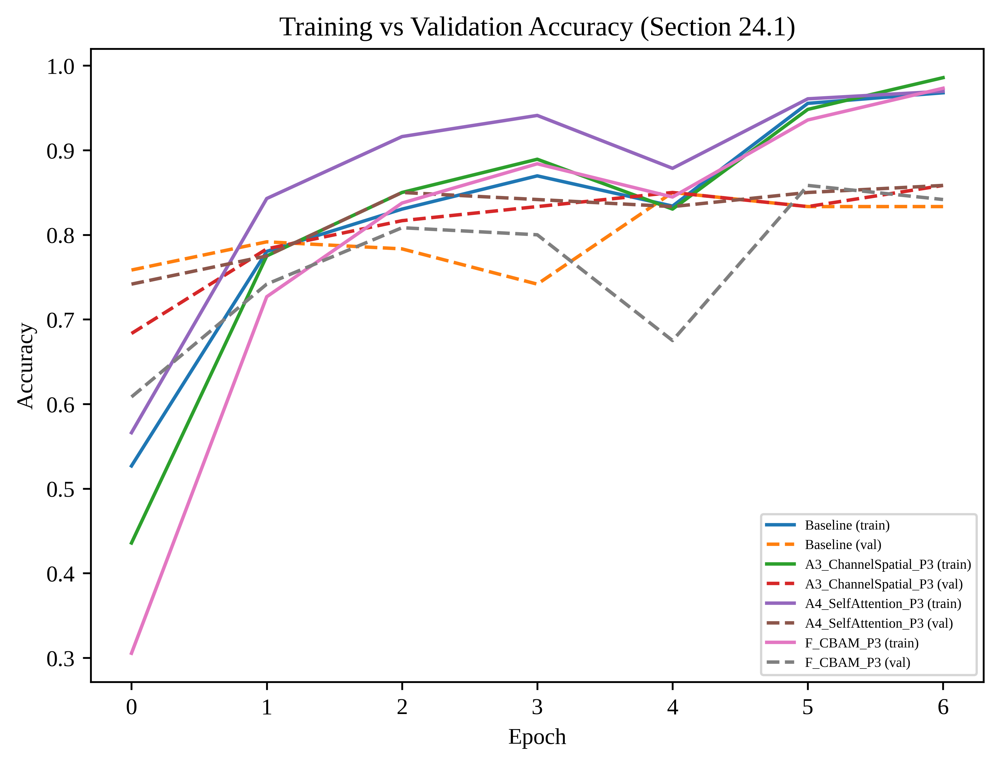

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


saved loss_curves.eps


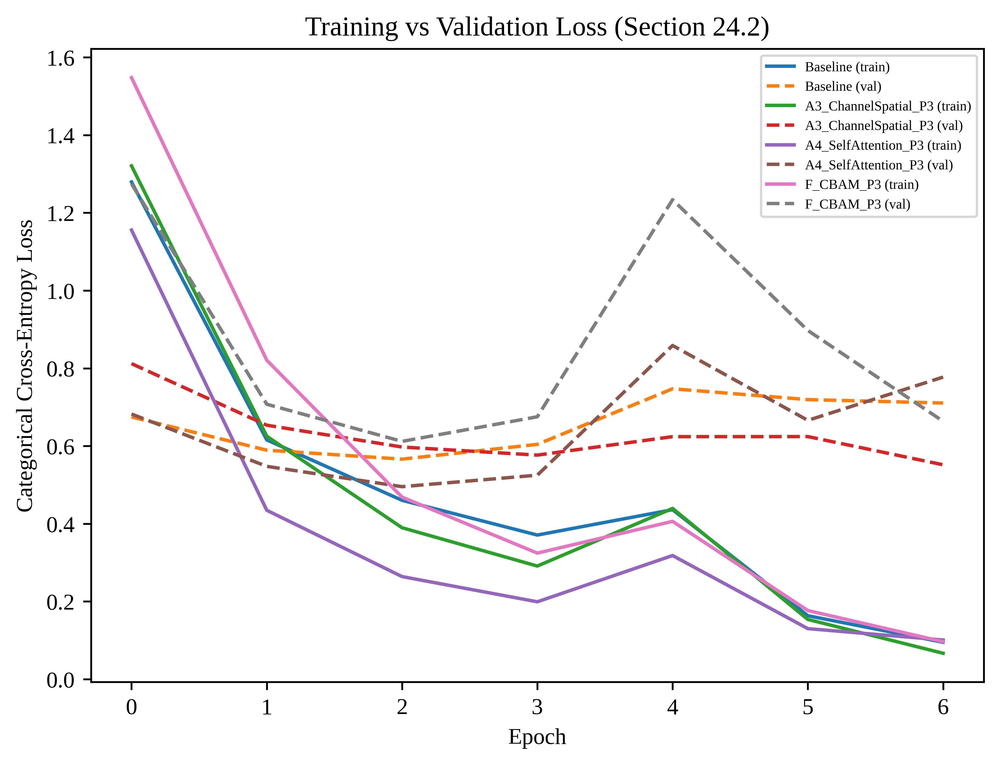

In [48]:
# 24.1 / 24.2: training/validation accuracy & loss curves, baseline vs a few
# representative attention models
curve_models = ["Baseline", "A3_ChannelSpatial_P3", "A4_SelfAttention_P3", "F_CBAM_P3"]

plt.figure(figsize=(7, 5))
for m in curve_models:
    h = histories[m]
    plt.plot(h['accuracy'], linestyle='-', label=f"{m} (train)")
    plt.plot(h['val_accuracy'], linestyle='--', label=f"{m} (val)")
plt.xlabel("Epoch"); plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy (Section 24.1)")
plt.legend(fontsize=6)
save_plot("accuracy_curves")
plt.show()

plt.figure(figsize=(7, 5))
for m in curve_models:
    h = histories[m]
    plt.plot(h['loss'], linestyle='-', label=f"{m} (train)")
    plt.plot(h['val_loss'], linestyle='--', label=f"{m} (val)")
plt.xlabel("Epoch"); plt.ylabel("Categorical Cross-Entropy Loss")
plt.title("Training vs Validation Loss (Section 24.2)")
plt.legend(fontsize=6)
save_plot("loss_curves")
plt.show()

# Inference: compare, across these curves, whether attention (a) reaches a
# given accuracy/loss in fewer epochs than the baseline (faster convergence),
# (b) keeps a smaller train-val gap (less overfitting) or a larger one, and
# (c) trains smoothly or shows unstable spikes - report what this run shows.

saved attention_type_bar_charts.eps


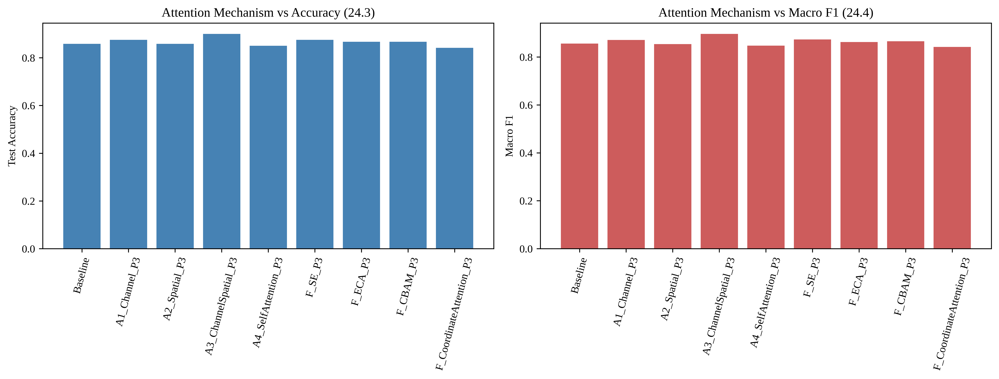

In [49]:
# 24.3 / 24.4: attention mechanism vs accuracy / macro F1 bar charts
bar_models = ["Baseline", "A1_Channel_P3", "A2_Spatial_P3", "A3_ChannelSpatial_P3",
              "A4_SelfAttention_P3", "F_SE_P3", "F_ECA_P3", "F_CBAM_P3", "F_CoordinateAttention_P3"]
bar_df = results_df[results_df["Model"].isin(bar_models)]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(bar_df["Model"], bar_df["Accuracy"], color='steelblue')
axes[0].set_ylabel("Test Accuracy"); axes[0].set_title("Attention Mechanism vs Accuracy (24.3)")
axes[0].tick_params(axis='x', rotation=75)
axes[1].bar(bar_df["Model"], bar_df["F1"], color='indianred')
axes[1].set_ylabel("Macro F1"); axes[1].set_title("Attention Mechanism vs Macro F1 (24.4)")
axes[1].tick_params(axis='x', rotation=75)
plt.tight_layout()
save_plot("attention_type_bar_charts")
plt.show()

saved accuracy_vs_parameters.eps


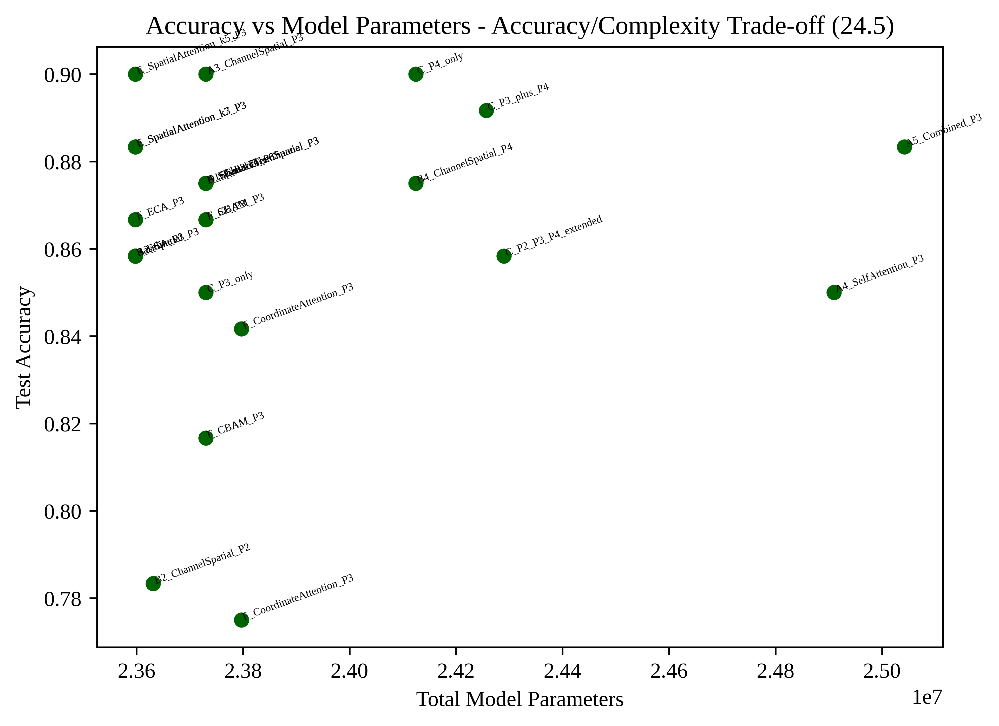

saved f1_vs_inference_time.eps


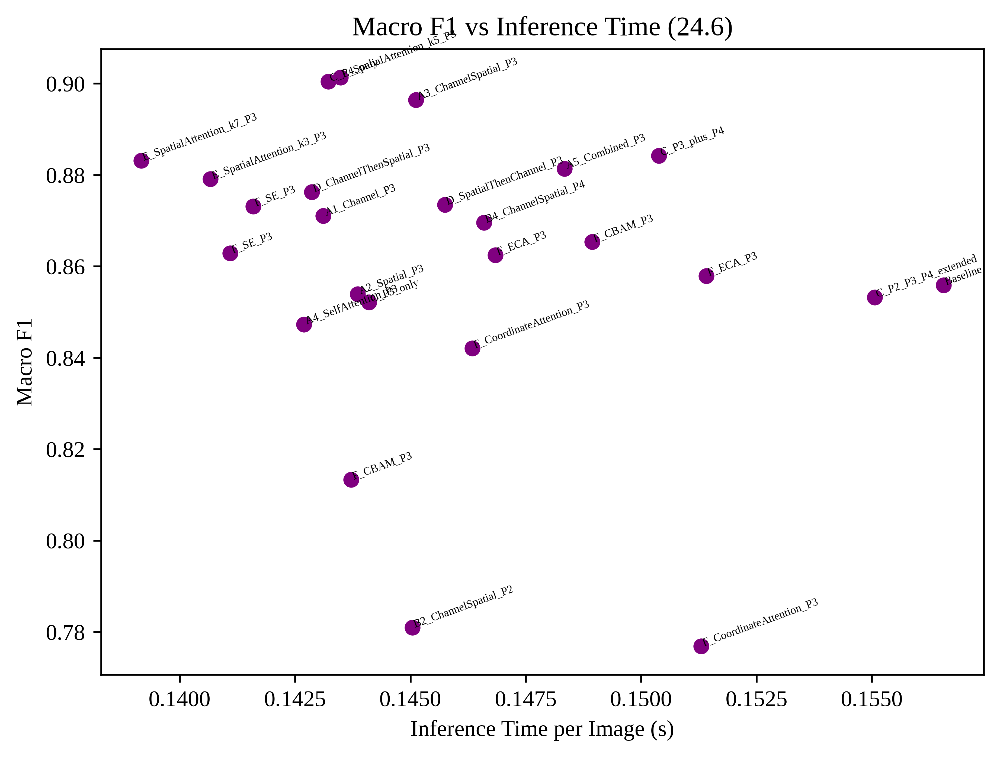

In [50]:
# 24.5 / 24.6: accuracy-vs-parameters and macro-F1-vs-inference-time scatter plots
plt.figure(figsize=(7, 5))
plt.scatter(results_df["Total Params"], results_df["Accuracy"], c='darkgreen')
for _, r in results_df.iterrows():
    plt.annotate(r["Model"], (r["Total Params"], r["Accuracy"]), fontsize=5, rotation=20)
plt.xlabel("Total Model Parameters"); plt.ylabel("Test Accuracy")
plt.title("Accuracy vs Model Parameters - Accuracy/Complexity Trade-off (24.5)")
save_plot("accuracy_vs_parameters")
plt.show()

plt.figure(figsize=(7, 5))
plt.scatter(results_df["Inference Time (s/img)"], results_df["F1"], c='purple')
for _, r in results_df.iterrows():
    plt.annotate(r["Model"], (r["Inference Time (s/img)"], r["F1"]), fontsize=5, rotation=20)
plt.xlabel("Inference Time per Image (s)"); plt.ylabel("Macro F1")
plt.title("Macro F1 vs Inference Time (24.6)")
save_plot("f1_vs_inference_time")
plt.show()

# Inference: a point that sits above-left of the general trend in the first
# plot (high accuracy for relatively few parameters) and above-left in the
# second (high F1 for low inference time) is the most favourable trade-off -
# identify that model from this run's data instead of assuming self-attention
# or the largest module automatically "wins".

## Section 25: Confusion Matrix Analysis

Best attention model by Macro F1: E_SpatialAttention_k5_P3
saved confusion_matrix_baseline.eps


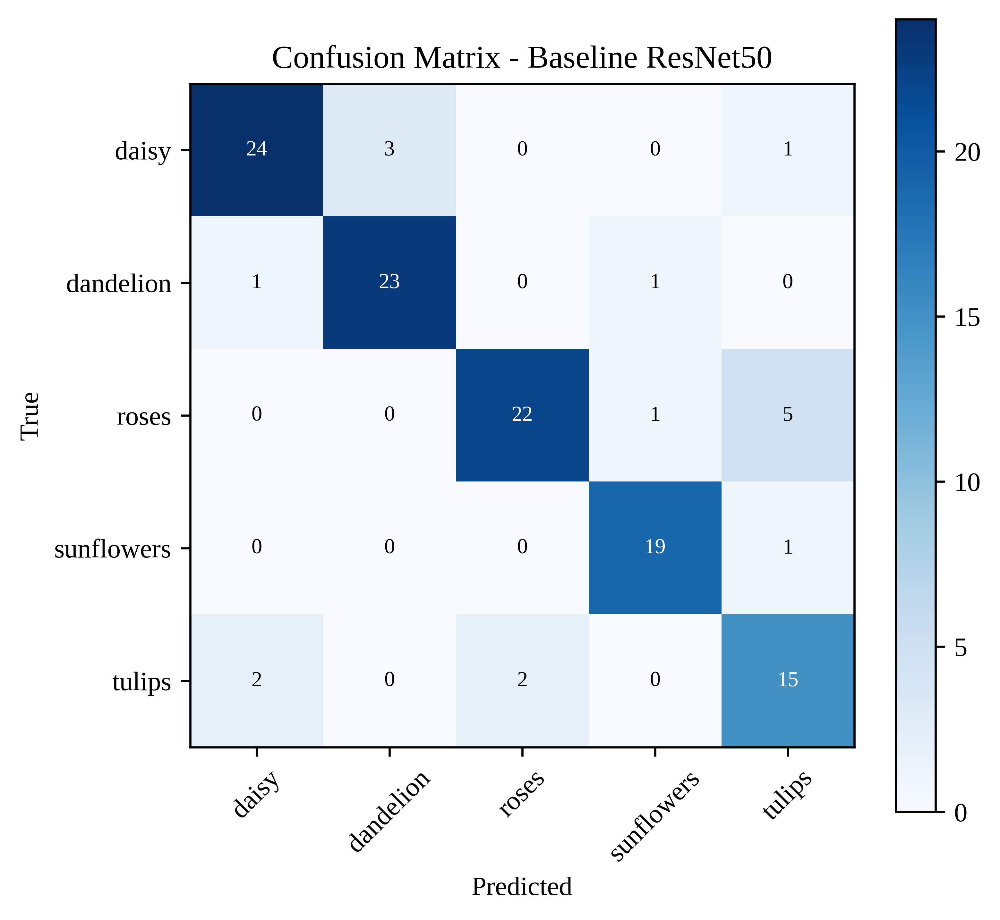

[E_SpatialAttention_k5_P3] acc=0.900 prec=0.912 rec=0.895 f1=0.901 params=23,598,008 inf=120.1 ms/img
saved confusion_matrix_best_attention.eps


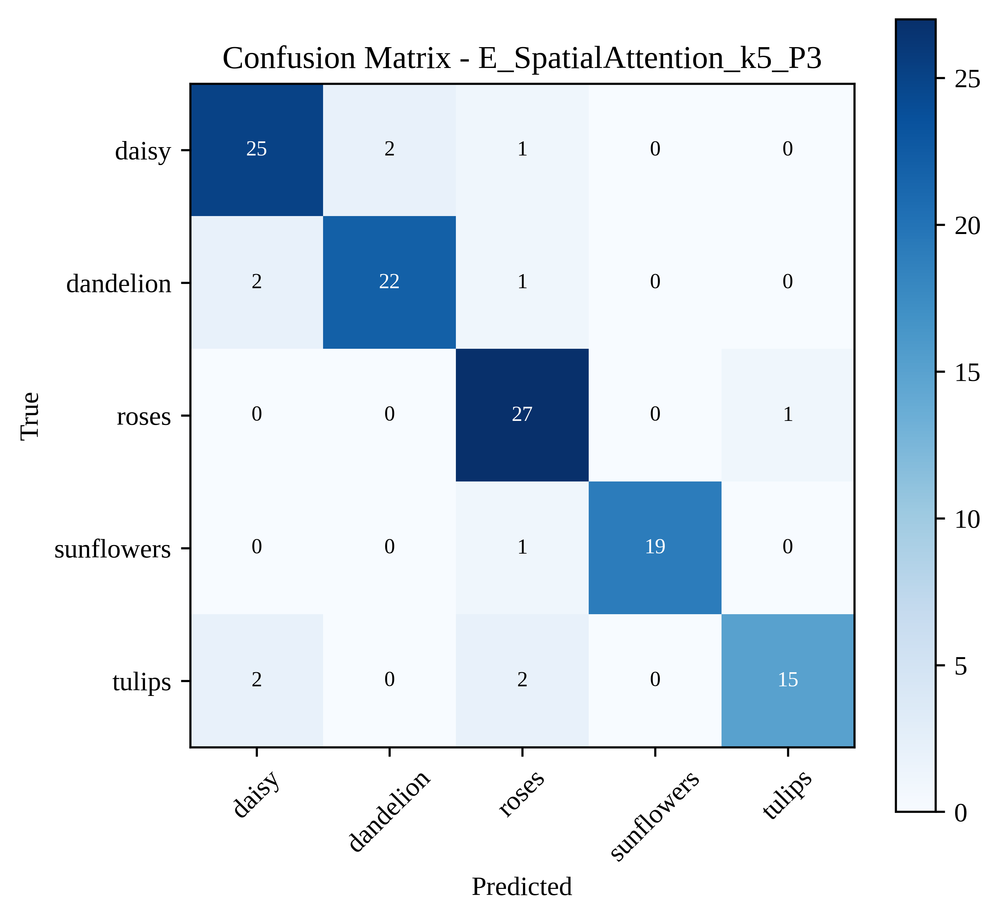

In [51]:
def plot_confusion_matrix(cm, title, filename):
    plt.figure(figsize=(5.5, 5))
    plt.imshow(cm, cmap='Blues')
    plt.colorbar()
    plt.xticks(range(NUM_CLASSES), CLASS_NAMES, rotation=45)
    plt.yticks(range(NUM_CLASSES), CLASS_NAMES)
    for i in range(NUM_CLASSES):
        for j in range(NUM_CLASSES):
            plt.text(j, i, cm[i, j], ha='center', va='center',
                      color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=8)
    plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(title)
    plt.tight_layout()
    save_plot(filename)
    plt.show()


best_attention_name = results_df.loc[
    results_df["Model"] != "Baseline", "F1"].astype(float).idxmax()
best_attention_name = results_df.loc[best_attention_name, "Model"]
print("Best attention model by Macro F1:", best_attention_name)

plot_confusion_matrix(cm_baseline, "Confusion Matrix - Baseline ResNet50", "confusion_matrix_baseline")
_, cm_best, _ = evaluate_model(trained_models[best_attention_name], best_attention_name)
plot_confusion_matrix(cm_best, f"Confusion Matrix - {best_attention_name}", "confusion_matrix_best_attention")

# Inference: compare the two matrices class by class - look for the
# off-diagonal cell(s) that shrink the most under attention (the class pair
# the model confuses less often) and whether the improvement in overall
# accuracy is spread across all five classes or concentrated in one or two.

## Sections 26-28: Qualitative Analysis - Grad-CAM and Internal Attention Maps

saved gradcam_baseline_vs_attention.eps


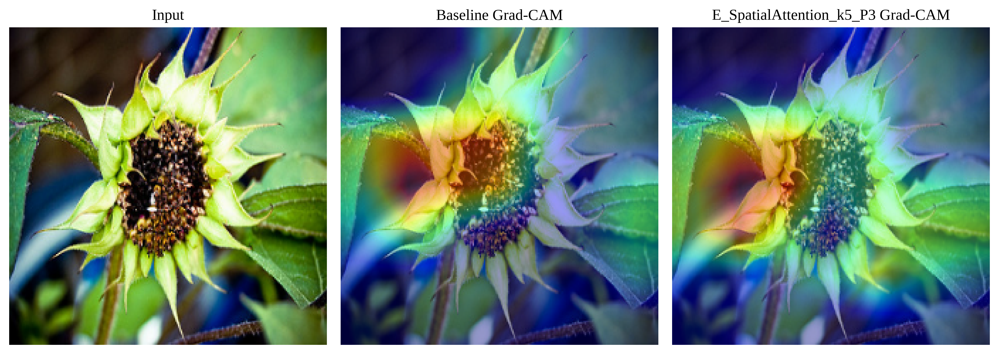

In [53]:
def grad_cam(model, img_array, last_conv_layer_name, class_index=None):
    """Section 27: Grad-CAM. alpha_k^c = GAP of dL^c/dA^k ; L^c = ReLU(sum_k alpha_k^c A^k)."""
    grad_model = Model(model.inputs, [get_layer_output(model, last_conv_layer_name), model.output])
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(img_array[np.newaxis, ...])
        if class_index is None:
            class_index = tf.argmax(preds[0])
        class_score = preds[:, class_index]
    grads = tape.gradient(class_score, conv_out)
    alpha = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.reduce_sum(alpha * conv_out[0], axis=-1)
    cam = tf.nn.relu(cam)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy()


def overlay_heatmap(image_uint8, heatmap, alpha=0.4):
    heatmap_resized = tf.image.resize(heatmap[..., np.newaxis], (IMG_SIZE, IMG_SIZE)).numpy()[..., 0]
    heatmap_rgb = plt.cm.jet(heatmap_resized)[..., :3]
    return (alpha * heatmap_rgb * 255 + (1 - alpha) * image_uint8).astype('uint8')


sample_idx = 0
sample_img_raw = x_test_raw[sample_idx]
sample_img_pp = x_test_pp[sample_idx]

baseline_cam = grad_cam(trained_models["Baseline"], sample_img_pp, "conv5_block3_out")
attn_cam = grad_cam(trained_models[best_attention_name], sample_img_pp, "conv5_block3_out")

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
axes[0].imshow(sample_img_raw); axes[0].set_title("Input"); axes[0].axis('off')
axes[1].imshow(overlay_heatmap(sample_img_raw, baseline_cam)); axes[1].set_title("Baseline Grad-CAM"); axes[1].axis('off')
axes[2].imshow(overlay_heatmap(sample_img_raw, attn_cam)); axes[2].set_title(f"{best_attention_name} Grad-CAM"); axes[2].axis('off')
plt.tight_layout()
save_plot("gradcam_baseline_vs_attention")
plt.show()

# Inference (Section 27.1 - evidence-based, not "better/worse"): describe
# where each heatmap concentrates for this specific image - e.g. whether the
# attention model's activation sits more tightly on the flower/petals and
# less on background/leaves than the baseline's, based on what is visible
# above for this particular sample.

Feature map shape before attention: (14, 14, 1024)  after attention: (14, 14, 1024)  (dimension-preserving, as expected)
saved feature_map_before_after_attention.eps


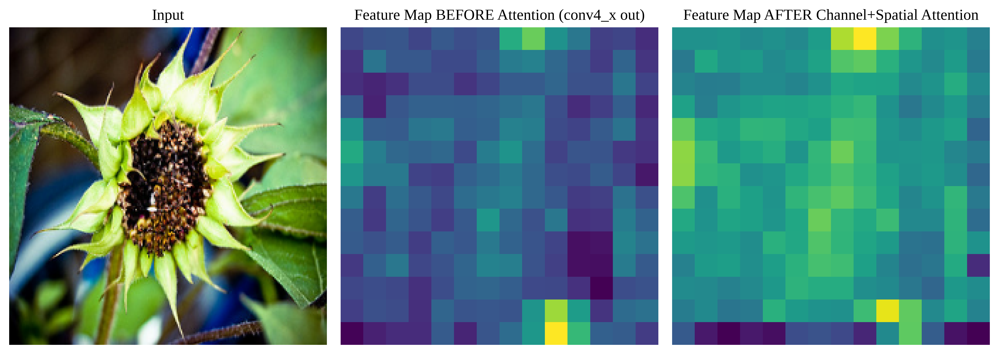

In [54]:
# Section 31.5 / 31.10, Section 26 "intermediate feature maps": the backbone
# feature map immediately BEFORE the attention block vs. immediately AFTER
# it, for the Channel+Spatial @ P3 model (A3). Both are averaged over the
# channel axis (-> a single H x W map) purely for display purposes; the
# attention block itself is channel/spatial-attention and does not change
# the tensor's spatial or channel dimensions (see the per-insertion shape
# printout from build_attention_model above).
a3_model = trained_models["A3_ChannelSpatial_P3"]
pre_attn_tensor = get_layer_output(a3_model, STAGE_TO_LAYER["P3"])        # conv4_block6_out, before attention
post_attn_tensor = get_layer_output(a3_model, "a3_csa_s_scale")            # output of the spatial-attention scale, after attention
feature_map_probe = Model(a3_model.inputs, [pre_attn_tensor, post_attn_tensor])
pre_fmap, post_fmap = feature_map_probe.predict(sample_img_pp[np.newaxis, ...], verbose=0)
pre_fmap_avg = pre_fmap[0].mean(axis=-1)
post_fmap_avg = post_fmap[0].mean(axis=-1)
print(f"Feature map shape before attention: {pre_fmap.shape[1:]}  "
      f"after attention: {post_fmap.shape[1:]}  (dimension-preserving, as expected)")

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
axes[0].imshow(sample_img_raw); axes[0].set_title("Input"); axes[0].axis('off')
axes[1].imshow(pre_fmap_avg, cmap='viridis'); axes[1].set_title("Feature Map BEFORE Attention (conv4_x out)"); axes[1].axis('off')
axes[2].imshow(post_fmap_avg, cmap='viridis'); axes[2].set_title("Feature Map AFTER Channel+Spatial Attention"); axes[2].axis('off')
plt.tight_layout()
save_plot("feature_map_before_after_attention")
plt.show()

# Inference: both maps have identical spatial/channel dimensions (attention
# only reweights, it does not resize); compare whether the AFTER map
# concentrates its activation more tightly on the flower region (channels
# and/or locations unrelated to the flower suppressed) than the BEFORE map.

saved channel_attention_weights.eps


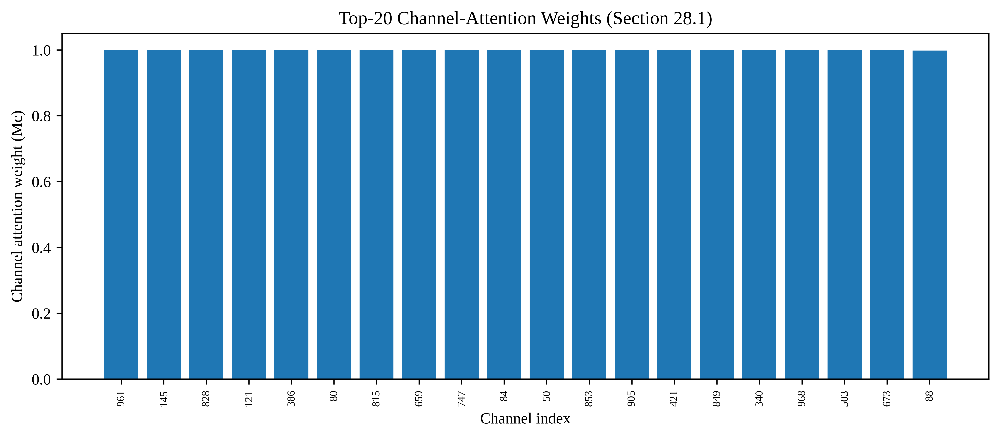

In [55]:
# Section 28.1: channel-attention weights (top-K bar chart) for a model that
# used plain channel attention at P3 (A1)
ca_model = trained_models["A1_Channel_P3"]
ca_weight_model = Model(ca_model.inputs, get_layer_output(ca_model, "a1_ca_fc2"))
channel_weights = ca_weight_model.predict(sample_img_pp[np.newaxis, ...], verbose=0)[0]
K = 20
top_k_idx = np.argsort(channel_weights)[::-1][:K]

plt.figure(figsize=(9, 4))
plt.bar(range(K), channel_weights[top_k_idx])
plt.xticks(range(K), top_k_idx, rotation=90, fontsize=7)
plt.xlabel("Channel index"); plt.ylabel("Channel attention weight (Mc)")
plt.title(f"Top-{K} Channel-Attention Weights (Section 28.1)")
plt.tight_layout()
save_plot("channel_attention_weights")
plt.show()

saved spatial_attention_map_overlay.eps


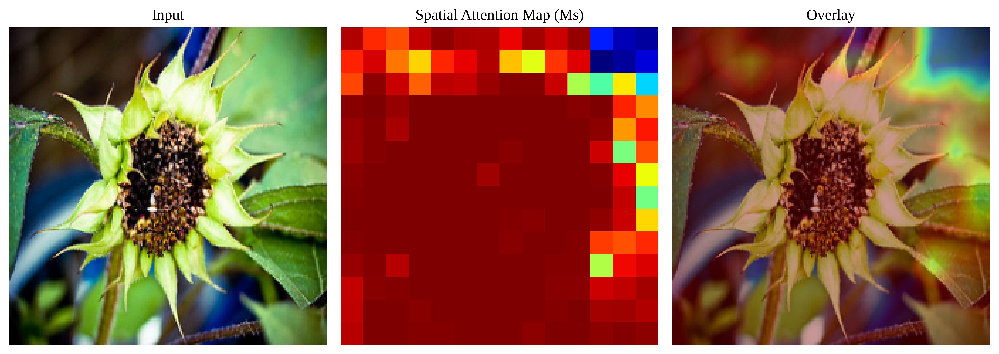

In [56]:
# Section 28.2: spatial-attention heatmap + overlay for a model that used
# plain spatial attention at P3 (A2)
sa_model = trained_models["A2_Spatial_P3"]
sa_map_model = Model(sa_model.inputs, get_layer_output(sa_model, "a2_sa_map"))
spatial_map = sa_map_model.predict(sample_img_pp[np.newaxis, ...], verbose=0)[0, ..., 0]

fig, axes = plt.subplots(1, 3, figsize=(11, 4))
axes[0].imshow(sample_img_raw); axes[0].set_title("Input"); axes[0].axis('off')
axes[1].imshow(spatial_map, cmap='jet'); axes[1].set_title("Spatial Attention Map (Ms)"); axes[1].axis('off')
axes[2].imshow(overlay_heatmap(sample_img_raw, spatial_map)); axes[2].set_title("Overlay"); axes[2].axis('off')
plt.tight_layout()
save_plot("spatial_attention_map_overlay")
plt.show()

saved self_attention_response.eps


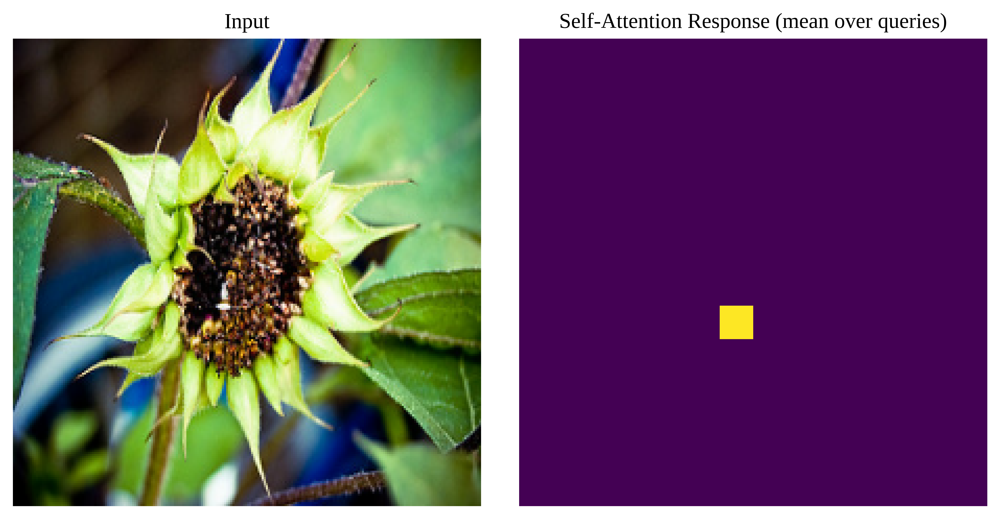

In [57]:
# Section 28.3: self-attention response (mean attention over all query
# locations), for the A4 self-attention model
self_model = trained_models["A4_SelfAttention_P3"]
self_attn_model = Model(self_model.inputs, get_layer_output(self_model, "a4_self_softmax"))
attn_matrix = self_attn_model.predict(sample_img_pp[np.newaxis, ...], verbose=0)[0]  # (N, N)
mean_response = attn_matrix.mean(axis=0)                     # average attention received by each location
side = int(np.sqrt(mean_response.shape[0]))
self_response_map = mean_response.reshape(side, side)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(sample_img_raw); axes[0].set_title("Input"); axes[0].axis('off')
axes[1].imshow(self_response_map, cmap='viridis'); axes[1].set_title("Self-Attention Response (mean over queries)")
axes[1].axis('off')
plt.tight_layout()
save_plot("self_attention_response")
plt.show()

# Inference (Sections 28.1-28.3): a small number of channels dominating the
# bar chart means the network relies on a few highly-informative feature
# maps rather than weighting all channels evenly; the spatial map should
# highlight the flower region more than the background if spatial attention
# is working as intended; the self-attention response shows which locations
# other locations most often attend to (often the flower's central region,
# since petals/centre are mutually informative about the class).

## Section 29: Attention Position Visualization (P2, P3, P4 on the same image)

saved attention_position_comparison.eps


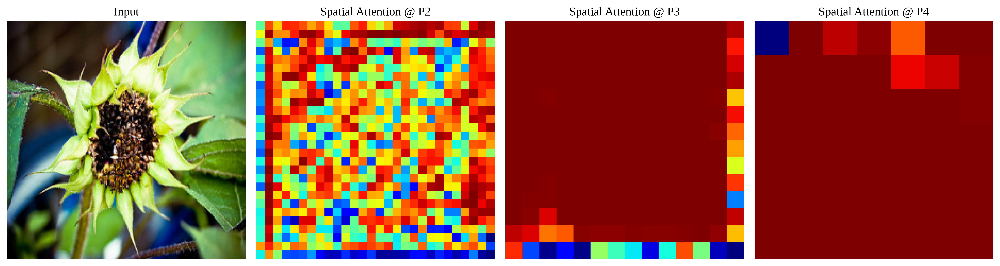

In [58]:
pos_models = {"P2": trained_models["B2_ChannelSpatial_P2"],
              "P3": trained_models["A3_ChannelSpatial_P3"],
              "P4": trained_models["B4_ChannelSpatial_P4"]}
pos_layer_suffix = {"P2": "b2_csa_s_map", "P3": "a3_csa_s_map", "P4": "b4_csa_s_map"}

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes[0].imshow(sample_img_raw); axes[0].set_title("Input"); axes[0].axis('off')
for i, (label, mdl) in enumerate(pos_models.items(), start=1):
    probe = Model(mdl.inputs, get_layer_output(mdl, pos_layer_suffix[label]))
    smap = probe.predict(sample_img_pp[np.newaxis, ...], verbose=0)[0, ..., 0]
    axes[i].imshow(smap, cmap='jet'); axes[i].set_title(f"Spatial Attention @ {label}"); axes[i].axis('off')
plt.tight_layout()
save_plot("attention_position_comparison")
plt.show()

# Inference: compare resolution and what each map seems to respond to - P2's
# map operates on 28x28 (intermediate) features and tends to be finer-grained
# and texture/edge sensitive, while P4's map operates on 7x7 (deep, low-
# resolution) features and tends to highlight broad semantic regions. Confirm
# this against what the three panels above actually show for this image.

## Section 30: Qualitative Comparison Across Attention Mechanisms
## (correctly and incorrectly classified images)

In [59]:
_, _, y_pred_baseline = evaluate_model(trained_models["Baseline"], "Baseline (recheck)")
correct_idx = np.where(y_pred_baseline == y_test)[0][:3]
incorrect_idx = np.where(y_pred_baseline != y_test)[0][:2]
qual_idx = np.concatenate([correct_idx, incorrect_idx])

qual_models = {"Baseline": trained_models["Baseline"],
               "Channel (A1)": trained_models["A1_Channel_P3"],
               "Spatial (A2)": trained_models["A2_Spatial_P3"],
               "Channel+Spatial (A3)": trained_models["A3_ChannelSpatial_P3"],
               # Section 36 requires BOTH a quantitative and a qualitative
               # comparison for the additional mechanisms - these two columns
               # provide the qualitative (Grad-CAM) half, matching the
               # quantitative rows already in results_df (Section 19).
               "ECA": trained_models["F_ECA_P3"],
               "Coordinate Attn.": trained_models["F_CoordinateAttention_P3"]}

fig, axes = plt.subplots(len(qual_idx), len(qual_models) + 1,
                          figsize=(3 * (len(qual_models) + 1), 3 * len(qual_idx)))
for r, idx in enumerate(qual_idx):
    img_raw, img_pp = x_test_raw[idx], x_test_pp[idx]
    axes[r, 0].imshow(img_raw)
    tag = "correct" if idx in correct_idx else "incorrect"
    axes[r, 0].set_title(f"Input ({tag}, true={CLASS_NAMES[y_test[idx]]})", fontsize=8)
    axes[r, 0].axis('off')
    for c, (mname, mdl) in enumerate(qual_models.items(), start=1):
        cam = grad_cam(mdl, img_pp, "conv5_block3_out")
        axes[r, c].imshow(overlay_heatmap(img_raw, cam))
        axes[r, c].set_title(mname, fontsize=8)
        axes[r, c].axis('off')
plt.tight_layout()
save_plot("qualitative_comparison_grid")
plt.show()

# Inference (Section 30.1): on the correctly-classified rows, attention models
# should generally localise the flower more compactly than the baseline; on
# the incorrectly-classified rows, check whether the attention models' focus
# moved to a plausible-but-wrong region (e.g. background clutter or a leaf)
# versus the baseline's focus, which can help explain the misclassification.

[Baseline (recheck)] acc=0.858 prec=0.855 rec=0.860 f1=0.856 params=23,597,957 inf=105.5 ms/img
saved qualitative_comparison_grid.eps


## Section 32: Recommended Visualization Layout (extended, optional)
`Input | Baseline | SE | ECA | CBAM | Self-Attention`, all at P3, for one
representative test image.

saved extended_comparison_layout.eps





In [60]:
extended_layout_models = {"Baseline": trained_models["Baseline"],
                           "SE": trained_models["F_SE_P3"],
                           "ECA": trained_models["F_ECA_P3"],
                           "CBAM": trained_models["F_CBAM_P3"],
                           "Self-Attention": trained_models["A4_SelfAttention_P3"]}

fig, axes = plt.subplots(1, len(extended_layout_models) + 1,
                          figsize=(3 * (len(extended_layout_models) + 1), 3.2))
axes[0].imshow(sample_img_raw); axes[0].set_title("Input"); axes[0].axis('off')
for c, (mname, mdl) in enumerate(extended_layout_models.items(), start=1):
    cam = grad_cam(mdl, sample_img_pp, "conv5_block3_out")
    axes[c].imshow(overlay_heatmap(sample_img_raw, cam))
    axes[c].set_title(mname, fontsize=9)
    axes[c].axis('off')
plt.tight_layout()
save_plot("extended_comparison_layout")
plt.show()

## Section 33: Required Experimental Analysis Summary

In [61]:
print("\n33.1 Quantitative Analysis (Accuracy / Precision / Recall / Macro F1):")
print(results_df[["Model", "Position", "Accuracy", "Precision", "Recall", "F1"]].to_string(index=False))

print("\n33.2 Complexity Analysis (Parameters / Inference Time):")
print(results_df[["Model", "Trainable Params", "Total Params", "Inference Time (s/img)"]].to_string(index=False))

print("\n33.3 Qualitative Analysis: see the Grad-CAM, spatial/channel/self-attention")
print("and attention-position figures saved above (Sections 26-30).")

results_df.to_csv("experiment_8_9_results.csv", index=False)
print("\nSaved full result table to experiment_8_9_results.csv")


33.1 Quantitative Analysis (Accuracy / Precision / Recall / Macro F1):
                   Model           Position  Accuracy  Precision   Recall       F1
                Baseline                  -  0.858333   0.855350 0.860466 0.855876
           A1_Channel_P3                 P3  0.875000   0.870661 0.876135 0.871040
           A2_Spatial_P3                 P3  0.858333   0.856422 0.857038 0.853905
    A3_ChannelSpatial_P3                 P3  0.900000   0.895722 0.900707 0.896405
     A4_SelfAttention_P3                 P3  0.850000   0.854795 0.854421 0.847289
          A5_Combined_P3                 P3  0.883333   0.881965 0.882421 0.881357
    B2_ChannelSpatial_P2                 P2  0.783333   0.792781 0.781654 0.780963
    B4_ChannelSpatial_P4                 P4  0.875000   0.872142 0.867654 0.869543
               C_P3_only             ['P3']  0.850000   0.860792 0.855519 0.852158
               C_P4_only             ['P4']  0.900000   0.904915 0.900421 0.900450
            C_P

## Sections 1-2, 37: Discussion / Answers to the Required Questions

1. Residual connections let each block learn a residual F(x) added back to
   its input (y = F(x) + x), so gradients have a direct path to earlier
   layers; this prevents the vanishing-gradient/degradation problem that
   made very deep plain CNNs hard to train before ResNet.
2. conv2_x produces high-resolution (56x56), low-channel (256) features
   carrying mostly low-level visual information; conv5_x produces low-
   resolution (7x7), high-channel (2048) features carrying high-level,
   class-discriminative semantic information.
3. Spatial resolution falls because of strided convolutions/pooling at the
   start of each stage, which progressively summarise larger image regions
   into each feature-map location, trading spatial detail for larger
   receptive field and more abstract representation.
4. Channel count rises so the network can represent an increasing variety
   of learned patterns/concepts at each depth, compensating for the lost
   spatial resolution with a richer per-location feature vector.
5. Low-level features are edges/colours/textures; intermediate features are
   parts, local patterns and shape fragments (e.g. petal arrangements);
   high-level features are whole-object/semantic representations tied
   directly to the output classes.
6. Attention lets the network re-weight its own intermediate features -
   emphasising informative channels or spatial regions - rather than
   treating every channel/location as equally important by default.
7. Channel attention learns which feature CHANNELS (i.e. which learned
   patterns) are most relevant for the current input.
8. Spatial attention learns which spatial LOCATIONS in the feature map are
   most relevant for the current input.
9. Channel attention reweights along the channel axis using a single scalar
   per channel (same scalar at every spatial location); spatial attention
   reweights along the spatial axes using a single scalar per location
   (same scalar across all channels at that location).
10. They answer different, complementary questions ("what" vs "where"), so
    chaining them lets the network first decide which channels matter and
    then, on that refined tensor, decide which locations matter.
11. At conv3_x the features are more texture/part-like, so channel
    attention there emphasises low/intermediate-level pattern detectors;
    at conv5_x the features are class-semantic, so the same mechanism
    emphasises whole-object/class-discriminative channels instead.
12. At an intermediate stage, spatial attention can suppress background
    clutter/distractor regions before the representation becomes fully
    global, helping later layers focus computation on the object.
13. Self-attention forms an N x N matrix over all H*W locations, so its
    memory and compute both scale quadratically with N = H*W; a high-
    resolution feature map makes N - and therefore the cost - very large.
14. The attention matrix grows quadratically: doubling resolution roughly
    quadruples N and therefore roughly 16x's the N x N matrix size.
15. Performance typically depends on how well the attended feature
    resolution/semantics match what the attention mechanism needs -
    results from Experiment 2 above show whether this run favoured an
    earlier or later position.
16. Attention at P2 operates on high-resolution, low-level features and
    tends to produce finer, texture/edge-like maps; attention at P4
    operates on coarse, semantic features and tends to produce broader,
    object-level maps (see the Section 29 figure).
17. Not necessarily - Experiment 3 above checks whether P3+P4 (or
    P2+P3+P4) actually beats a single well-placed position once the extra
    parameters/compute are accounted for.
18. They can, since each ordering applies a different reduction to the
    tensor the second module sees - Experiment 4 above compares them
    directly under identical settings.
19. A larger spatial kernel aggregates a wider local context before scoring
    each location, which can smooth/enlarge the attended regions - the
    Section 18 table shows the accuracy/F1/time trend for this run.
20. SE attention uses two fully-connected layers (with a reduction ratio)
    to mix information across ALL channels; ECA replaces this with a single
    lightweight 1D convolution over a LOCAL neighbourhood of channels,
    giving comparable performance with far fewer parameters.
21. CBAM applies channel attention first and then spatial attention in
    sequence (the same construction used here as channel_spatial_attention).
22. Self-attention relates every spatial location to every other location
    (modelling long-range spatial dependencies); channel attention only
    reweights channels and does not model spatial relationships at all.
23. No - Experiment 19's table lets you check directly whether the most
    parameter-heavy mechanism in this run actually achieved the best
    accuracy, or whether a lighter mechanism matched/beat it.
24. An internal attention map is produced during the forward pass as part
    of the model's computation (e.g. Mc, Ms above); Grad-CAM is produced
    AFTER a prediction, using gradients of the class score with respect to
    a chosen conv layer - it explains the prediction rather than being
    part of how the prediction was computed.
25. Because it is computed only after the forward pass and prediction are
    already complete, using gradients back-propagated from the output -
    it explains a decision that has already been made, rather than shaping
    the decision as it happens.
26. Compare the baseline and attention Grad-CAMs in Section 26 above for
    this run's sample image(s) and report what is visibly different.
27. Compare the qualitative grid in Section 30 - correctly and incorrectly
    classified rows - for differences in focus between the two groups.
28. Check the per-class diagonal values in the two confusion matrices
    (Section 25) to see which class(es) gained the most under attention.
29. A confusion matrix shows which SPECIFIC classes are confused with which
    other classes, not just how many predictions were right overall -
    overall accuracy alone cannot reveal this per-class error pattern.
30. Macro F1 weights every class equally regardless of its size, so it
    reveals poor performance on a minority/harder class that a single
    accuracy number (dominated by the easier/majority classes) can hide.
31. It is the balance between a model's classification quality (accuracy,
    F1) and its computational cost (parameters, inference time) - more
    complex attention is only worthwhile if it buys a meaningful quality
    gain (Section 24.5's scatter plot visualises this trade-off).
32. It is the analogous balance between macro F1 and inference time per
    image (Section 24.6's scatter plot) - whether added latency is repaid
    by a meaningful F1 improvement.
33. Using the same split for every ablation ensures observed performance
    differences are caused by the model change under study, not by
    different models happening to see easier/harder data subsets.
34. Keeping every other setting fixed isolates the one factor being studied
    (attention type, or position, or order, or kernel size) as the only
    possible explanation for any performance difference between runs.
35. The conclusions should be read directly off this script's own result
    table, curves, confusion matrices and qualitative figures above, rather
    than assumed in advance - that is the purpose of Section 33's summary.